In [39]:
import numpy as np
import pandas as pd
import os
import re
import seaborn as sns
import matplotlib.pyplot as plt
import json

In [40]:
default_config = {
    "clean_interval": 100,
    "cluster_interval": 1000,
    "decay_rate": 0.005,
    "min_num_mc": 5,
    "adaptive_threshold": 1,
    "sigma": 1.0,
    "threshold_momentum": 0.0,
    "use_heuristic": 1,
    "time_gap": 1000,
    "model": "sentenceTransformers",
}

In [41]:
# Read evaluation results
files = os.listdir("smac3_results_eval")
dfs = []
for file in files:
    if file.endswith(".json"):
        df = pd.read_csv(os.path.join("smac3_results_eval", file))
        dfs.append(df)
        
eval_df = pd.concat(dfs, ignore_index=True)
eval_df.head()

eval_df["dataset"] = eval_df["dataset"].str.replace("examples/data/", "").str.replace(".json", "")
# Replace "NTSO-T" with "NTSO" (typo in dataset names)
eval_df["dataset"] = eval_df["dataset"].str.replace("NTSO-T", "NTSO")

eval_df["is_train"] = eval_df["dataset"] != eval_df["loo_dataset"]

# Read configs

pareto_configs = []

for c in os.listdir("smac3_results"):
    with open(f"smac3_results/{c}", "r") as f:
        configs = json.load(f)
        for id, config in enumerate(configs):
            config["config_id"] = id
            config["config"] = c
            pareto_configs.append(config)

config_df = pd.DataFrame(pareto_configs)

# Merge with eval results
eval_df = pd.merge(eval_df, config_df, on=["config_id", "config"], how="left")
eval_df.loc[eval_df["config"] == "default", list(default_config.keys())] = eval_df.loc[eval_df["config"] == "default", list(default_config.keys())].fillna(pd.Series(default_config))
eval_df["is_default"] = eval_df["config"] == "default"

eval_full_df = eval_df.copy()
eval_no_default_df = eval_df[eval_df["config"] != "default"].copy()
eval_just_default_df = eval_df[eval_df["config"] == "default"].copy()

eval_df.head()

,dataset,neg_nmi,neg_throughput,config,config_id,loo_dataset,seed,is_train,adaptive_threshold,clean_interval,...,decay_rate,min_num_mc,model,use_heuristic,sigma,threshold_momentum,time_gap,min_weight,radius,is_default
0,Semantic10-T,-0.717274,-3.976666,best_config_loo_Trends-T_seed_4.json,0,Trends-T,4,True,1.0,113.0,...,0.001978,5.0,sentenceTransformers,1.0,2.945307,0.099512,804.405580,NaN,NaN,False
1,Semantic10-T,-0.618346,-3.940824,best_config_loo_Trends-T_seed_4.json,1,Trends-T,4,True,0.0,22.0,...,0.028400,1.0,sentenceTransformers,0.0,NaN,NaN,NaN,0.009475,0.513403,False
2,Semantic10-T,-0.756930,-3.989363,best_config_loo_Trends-T_seed_4.json,2,Trends-T,4,True,1.0,218.0,...,0.003711,21.0,sentenceTransformers,0.0,2.547533,0.126864,NaN,0.000149,NaN,False
3,Semantic10-T,-0.656280,-6.781712,best_config_loo_Trends-T_seed_4.json,3,Trends-T,4,True,1.0,418.0,...,0.013028,6.0,minishlab,0.0,2.942792,0.061913,NaN,0.000937,NaN,False
4,Semantic10-T,-0.455328,-7.120175,best_config_loo_Trends-T_seed_4.json,4,Trends-T,4,True,1.0,373.0,...,0.023029,6.0,minishlab,1.0,2.410031,0.349516,67.742663,NaN,NaN,False


In [42]:
from __future__ import annotations

import json
import re
from pathlib import Path
from typing import Any

import pandas as pd


_LOO_FOLDER_RE = re.compile(r"loo_(?P<loo_dataset>.+?)_seed_(?P<seed>[^/\\]+)")
_THROUGHPUT_RE = re.compile(r"Throughput\s+(?P<throughput>[0-9]*\.?[0-9]+)")


def _extract_metadata_from_path(path: Path) -> tuple[str | None, int | str | None]:
    for part in path.parts:
        match = _LOO_FOLDER_RE.fullmatch(part)
        if match:
            seed = match.group("seed")
            return match.group("loo_dataset"), int(seed) if seed.isdigit() else seed

    return None, None


def _extract_theoretical_throughput(additional_info: Any) -> float | None:
    if not isinstance(additional_info, dict):
        return None

    for key in ("error", "traceback"):
        value = additional_info.get(key)
        if not isinstance(value, str):
            continue

        match = _THROUGHPUT_RE.search(value)
        if match:
            return float(match.group("throughput"))

    return np.nan


def _flatten_configuration(configuration: Any) -> dict[str, Any]:
    if isinstance(configuration, dict):
        return dict(configuration)
    return {}


def _expand_costs(costs: Any) -> dict[str, Any]:
    if isinstance(costs, list):
        return {f"cost_{index + 1}": cost for index, cost in enumerate(costs)}
    if costs is None:
        return {}
    return {"cost_1": costs}


def runhistory_to_dataframe(runhistory_path: str | Path) -> pd.DataFrame:
    """Read one SMAC runhistory file into a flat dataframe.

    Each configuration option becomes its own column and each cost becomes its own column.
    """

    runhistory_path = Path(runhistory_path)
    loo_dataset, seed = _extract_metadata_from_path(runhistory_path)

    with runhistory_path.open() as file_handle:
        runhistory = json.load(file_handle)

    configs = runhistory.get("configs", {})
    rows: list[dict[str, Any]] = []

    for i, run in enumerate(runhistory.get("data", [])):
        config_id = run.get("config_id")
        config_key = str(config_id)
        configuration = configs.get(config_key, configs.get(config_id, {}))

        row = {
            "config_path": str(runhistory_path),
            "config_id": config_id,
            "run_index": i,
            "instance": run.get("instance"),
            "seed": seed,
            "loo_dataset": loo_dataset,
            "theoretical_throughput": _extract_theoretical_throughput(run.get("additional_info")),
        }
        row.update(_flatten_configuration(configuration))
        row.update(_expand_costs(run.get("cost")))
        rows.append(row)

    return pd.DataFrame(rows)


def runhistory_folder_to_dataframe(root_folder: str | Path) -> pd.DataFrame:
    """Read all runhistory files below a SMAC output root into one dataframe."""

    root_folder = Path(root_folder)
    runhistory_files = sorted(root_folder.rglob("runhistory.json"))

    if not runhistory_files:
        return pd.DataFrame(
            columns=["config_id", "instance", "seed", "loo_dataset", "theoretical_throughput", "run_index", "config_path"]
        )

    frames = [runhistory_to_dataframe(runhistory_file) for runhistory_file in runhistory_files]
    return pd.concat(frames, ignore_index=True)

runhistory_df = runhistory_folder_to_dataframe("smac3_output")
runhistory_df = runhistory_df.rename(columns={"cost_1": "neg_nmi", "cost_2": "neg_throughput"})
runhistory_df["instance"] = runhistory_df["instance"].str.replace("examples/data/", "").str.replace(".json", "")
runhistory_df["instance"] = runhistory_df["instance"].str.replace("NTSO-T", "NTSO")

runhistory_df.head()

,config_path,config_id,run_index,instance,seed,loo_dataset,theoretical_throughput,adaptive_threshold,clean_interval,cluster_interval,...,min_num_mc,model,use_heuristic,sigma,threshold_momentum,time_gap,neg_nmi,neg_throughput,min_weight,radius
0,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,1,0,Trends-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.857247,-3.917407,NaN,NaN
1,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,1,1,Semantic40-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.306003,-4.089985,NaN,NaN
2,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,2,Semantic40-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.520827,-4.193964,0.01,NaN
3,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,3,Trends-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.790788,-3.949290,0.01,NaN
4,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,4,News-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.763932,-4.229502,0.01,NaN


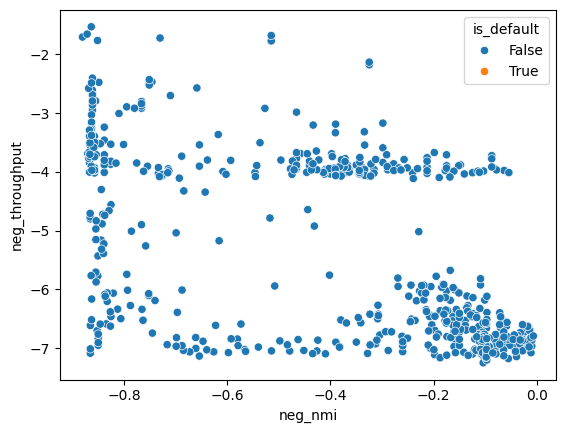

In [43]:
df = eval_df.copy()
df = df[(df["dataset"] == "NTSO") & (df["is_train"] == True)]

scatter = sns.scatterplot(df, x="neg_nmi", y="neg_throughput", hue="is_default")

(-1.0, 0.0)

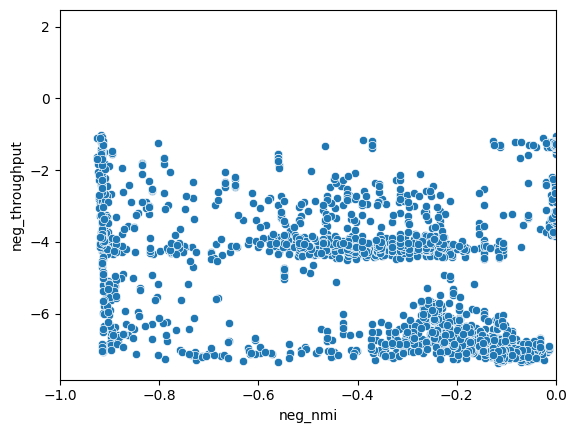

In [44]:
df = runhistory_df.copy()
df = df[df["instance"] == "NTSO"]

sns.scatterplot(df, x="neg_nmi", y="neg_throughput")

plt.xlim(-1.0, 0)

In [45]:
runhistory_df.head()

,config_path,config_id,run_index,instance,seed,loo_dataset,theoretical_throughput,adaptive_threshold,clean_interval,cluster_interval,...,min_num_mc,model,use_heuristic,sigma,threshold_momentum,time_gap,neg_nmi,neg_throughput,min_weight,radius
0,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,1,0,Trends-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.857247,-3.917407,NaN,NaN
1,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,1,1,Semantic40-T,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.306003,-4.089985,NaN,NaN
2,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,2,Semantic40-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.520827,-4.193964,0.01,NaN
3,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,3,Trends-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.790788,-3.949290,0.01,NaN
4,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,4,News-T,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.763932,-4.229502,0.01,NaN


(-1.0, 0.0)

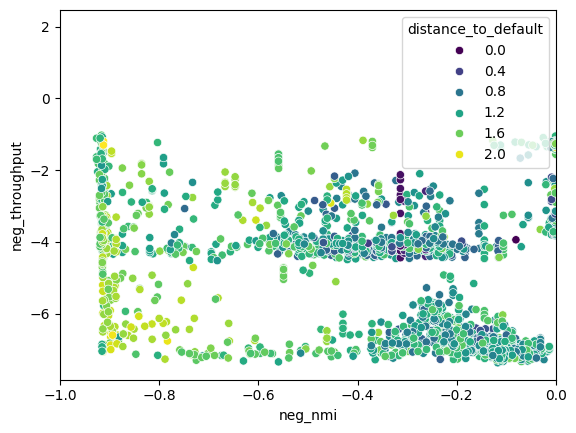

In [ ]:
df = runhistory_df.copy()
df = df[df["instance"] == "NTSO"]

#Append default
df["is_default"] = False

eval_ntso_df = eval_df[eval_df["dataset"] == "NTSO"]
eval_ntso_df["is_default"] = True

df = pd.concat([df, eval_just_default_df[eval_just_default_df["dataset"] == "NTSO"]], ignore_index=True)

model_ranking = {
    "minishlab" : 1,
    "sentenceTransformers" : 2,
    "maniac" : 3,
    "clips" : 4,
}
df["model"] = df["model"].map(model_ranking)

cols_to_normalize = [
   "model",
   "clean_interval",
   "cluster_interval",
   "decay_rate",
   "min_num_mc",
   "adaptive_threshold",
   "use_heuristic"
]

#Min-Max normalization for all columns except first 4 columns
mins = df[cols_to_normalize].min()
maxs = df[cols_to_normalize].max()
df[cols_to_normalize] = (df[cols_to_normalize] - mins) / (maxs - mins)

default_config_normalized = default_config.copy()
default_config_normalized["model"] = model_ranking[default_config["model"]]
for key in default_config_normalized:
    if key in mins and key in maxs:
        default_config_normalized[key] = (default_config_normalized[key] - mins[key]) / (maxs[key] - mins[key])
        
configs = df[cols_to_normalize].to_numpy()
comparable_default_config = [default_config_normalized[key] for key in cols_to_normalize]
        
df["distance_to_default"] = np.sqrt(np.sum((configs - comparable_default_config) ** 2, axis=1))
sns.scatterplot(df, x="neg_nmi", y="neg_throughput", hue="distance_to_default",  palette="viridis")
plt.xlim(-1.0, 0)

In [29]:
default_performances_df

,dataset,neg_nmi,neg_throughput,config,config_id,loo_dataset,seed,is_train,adaptive_threshold,clean_interval,cluster_interval,decay_rate,min_num_mc,model,use_heuristic,sigma,threshold_momentum,time_gap,min_weight,radius
5010,Semantic10-T,-0.663902,-4.021623,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5011,Semantic40-T,-0.462758,-3.989395,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5012,Semantic5-T,-0.801487,-4.006202,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5013,NT,-0.506142,-4.010698,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5014,NTS,-0.565318,-3.973737,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5015,NTSO,-0.080638,-3.941099,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5016,SO-T,-0.075348,-3.939008,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5017,News-T,-0.311444,-3.989944,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5018,Trends-T,-0.456637,-3.816268,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5019,Tweets-T,-0.629210,-3.893265,default,0,none,none,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
from pymoo.indicators.hv import Hypervolume

default_

ind = Hypervolume(ref_point=np.array([0, 0]))
